
# Salifort Motors: Employee Turnover Prediction

## Project Overview
This project uses employee data from Salifort Motors to investigate the factors associated with employee turnover and develop machine learning models to predict whether employees are likely to leave.

## Business Objective
- Explore patterns and factors associated with employee turnover.
- Build and evaluate classification models.
- Identify important predictors of employee departures.
- Provide data-driven recommendations to improve employee retention.

## PACE Framework
The project follows four stages:
**Plan → Analyze → Construct → Execute**

##  Import Libraries

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Model building
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

##  Load the Dataset

In [5]:
# Load the employee dataset
df = pd.read_csv('HR_capstone_dataset.csv')

# Display the first five rows
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


##  Initial Data Exploration

In [7]:

# Check the number of rows and columns
df.shape

(14999, 10)

In [8]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [9]:

# Check for missing values in each column
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Department               0
salary                   0
dtype: int64

In [10]:
# Count duplicate records
duplicates = df.duplicated().sum()

# Calculate percentage of duplicates
duplicate_percentage = (duplicates / len(df)) * 100

print(f"Duplicate records: {duplicates}")
print(f"Percentage of duplicates: {duplicate_percentage:.2f}%")

Duplicate records: 3008
Percentage of duplicates: 20.05%


In [11]:
# Summary statistics for numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803054,1.232592,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050337,49.943099,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498233,1.460136,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.144610,0.351719,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.238083,0.425924,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021268,0.144281,0.00,0.00,0.00,0.00,1.0


### Initial Data Exploration — Key Findings

- **Dataset:** 14,999 records and 10 variables, with no missing values.
- **Duplicates:** 3,008 records (20.05%) require removal.
- **Turnover:** 23.81% of employee records indicate departures.
- **Workforce:** Average satisfaction is 0.61, monthly working hours are 201, and tenure is 3.5 years.
- **Promotion:** Only 2.13% received a promotion in the last five years.

**Conclusion:** Duplicate records require cleaning before investigating employee turnover patterns.

##  Data Cleaning

In [14]:
# Remove duplicate records
df_clean = df.drop_duplicates().copy()

# Compare dataset dimensions
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Records removed:", len(df) - len(df_clean))

Original dataset: (14999, 10)
Cleaned dataset: (11991, 10)
Records removed: 3008


In [15]:
# Check for remaining duplicates and missing values
print("Remaining duplicates:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

Remaining duplicates: 0
Missing values: 0


In [16]:
# Employee turnover counts and percentages
turnover_counts = df_clean['left'].value_counts().sort_index()
turnover_percent = df_clean['left'].value_counts(normalize=True).sort_index() * 100

turnover_summary = pd.DataFrame({
    'Count': turnover_counts,
    'Percentage (%)': turnover_percent.round(2)
})
turnover_summary.index = ['Stayed', 'Left']
turnover_summary

,Count,Percentage (%)
Stayed,10000,83.4
Left,1991,16.6


In [17]:
# Display the first five cleaned records
df_clean.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Data Cleaning — Key Findings

- **Cleaned dataset:** 11,991 records and 10 variables.
- **Duplicates removed:** 3,008 (20.05%), with no remaining duplicates or missing values.
- **Employee turnover:** 10,000 employees stayed (83.40%), while 1,991 left (16.60%).

**Conclusion:** The dataset is ready for EDA. Employee turnover is imbalanced, which will be considered during model development.


##  Exploratory Data Analysis (EDA)

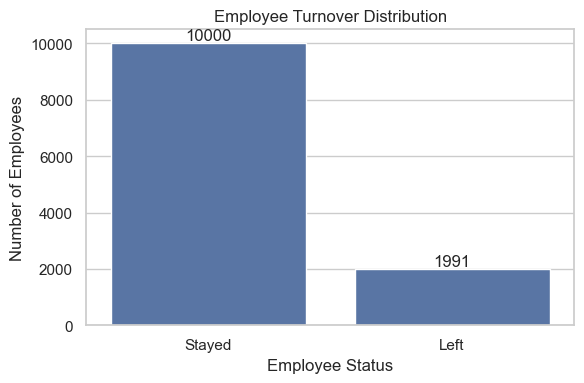

In [20]:
# Visualise employee turnover distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x='left')

ax.set_title('Employee Turnover Distribution')
ax.set_xlabel('Employee Status')
ax.set_ylabel('Number of Employees')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Stayed', 'Left'])

# Display counts above the bars
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig('employee_turnover_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

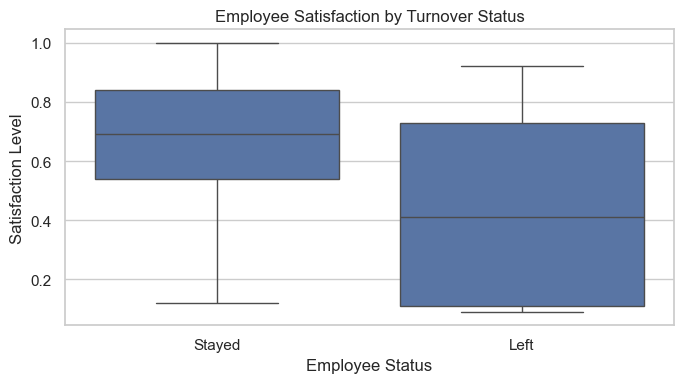

In [21]:
# Compare satisfaction levels by employee status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='left', y='satisfaction_level')

plt.title('Employee Satisfaction by Turnover Status')
plt.xlabel('Employee Status')
plt.ylabel('Satisfaction Level')
plt.xticks([0, 1], ['Stayed', 'Left'])

plt.tight_layout()
plt.savefig('employee_satisfaction_by_turnover.png', dpi=300, bbox_inches='tight')
plt.show()

### EDA — Initial Findings
- **Turnover:** 16.60% of employees left, indicating class imbalance.
- **Satisfaction:** Employees who left had a lower median satisfaction (0.41) than those who stayed (0.70).
**Insight:** Lower employee satisfaction is associated with higher turnover.

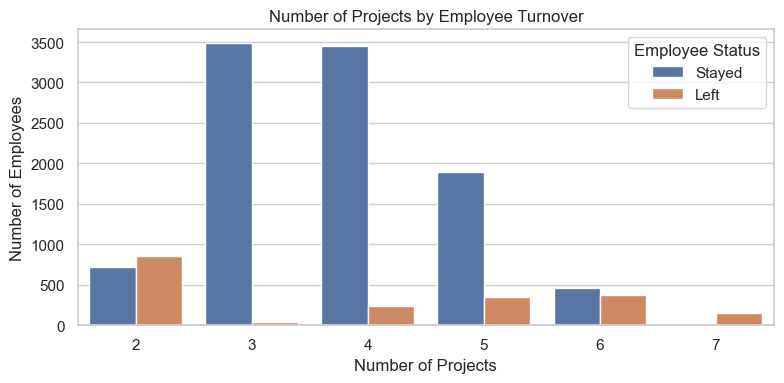

In [23]:
# Compare number of projects by turnover status
plt.figure(figsize=(8, 4))

sns.countplot(data=df_clean, x='number_project', hue='left')

plt.title('Number of Projects by Employee Turnover')
plt.xlabel('Number of Projects')
plt.ylabel('Number of Employees')
plt.legend(title='Employee Status', labels=['Stayed', 'Left'])

plt.tight_layout()
plt.show()

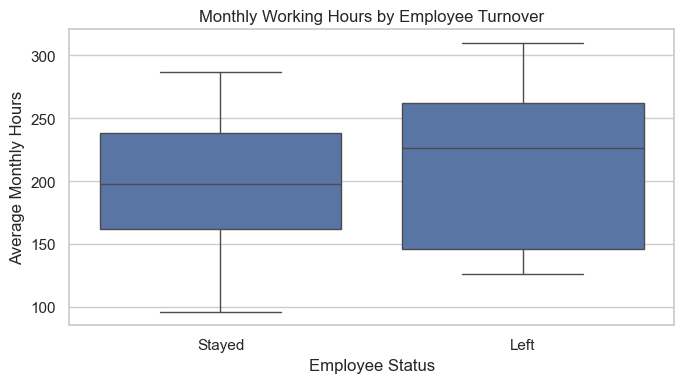

In [24]:
# Compare monthly working hours by turnover status
plt.figure(figsize=(7, 4))

sns.boxplot(data=df_clean, x='left', y='average_montly_hours')

plt.title('Monthly Working Hours by Employee Turnover')
plt.xlabel('Employee Status')
plt.ylabel('Average Monthly Hours')
plt.xticks([0, 1], ['Stayed', 'Left'])

plt.tight_layout()
plt.show()

### Workload Analysis — Key Findings

- **Projects:** Departures were concentrated among employees handling 2 or 6–7 projects, suggesting possible underutilisation or excessive workload.
- **Working hours:** Employees who left had higher median monthly hours (227) than those who stayed (198).

**Insight:** Workload imbalance may be associated with employee turnover.

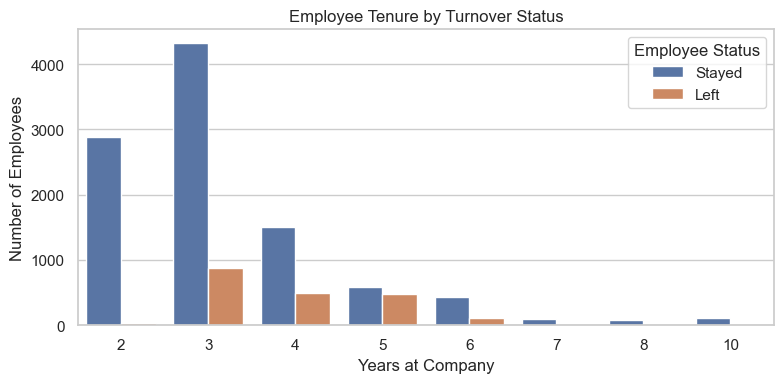

In [26]:
# Compare employee tenure by turnover status
plt.figure(figsize=(8, 4))

sns.countplot(data=df_clean, x='time_spend_company', hue='left')

plt.title('Employee Tenure by Turnover Status')
plt.xlabel('Years at Company')
plt.ylabel('Number of Employees')
plt.legend(title='Employee Status', labels=['Stayed', 'Left'])

plt.tight_layout()
plt.show()

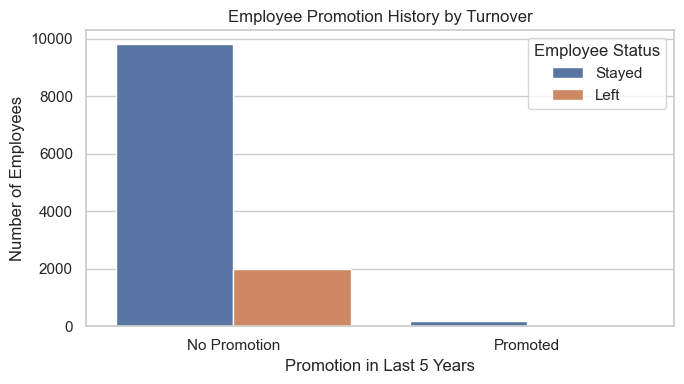

In [27]:
# Compare promotion history by turnover status
plt.figure(figsize=(7, 4))

sns.countplot(data=df_clean, x='promotion_last_5years', hue='left')

plt.title('Employee Promotion History by Turnover')
plt.xlabel('Promotion in Last 5 Years')
plt.ylabel('Number of Employees')
plt.xticks([0, 1], ['No Promotion', 'Promoted'])
plt.legend(title='Employee Status', labels=['Stayed', 'Left'])

plt.tight_layout()
plt.show()

### Tenure and Promotion — Key Findings

- **Tenure:** Employee departures were concentrated among those with 3–5 years of service.
- **Promotion:** Nearly all departing employees had not received a promotion in the previous five years.

**Insight:** Employee tenure and promotion history may be associated with turnover, although these relationships do not establish causation.

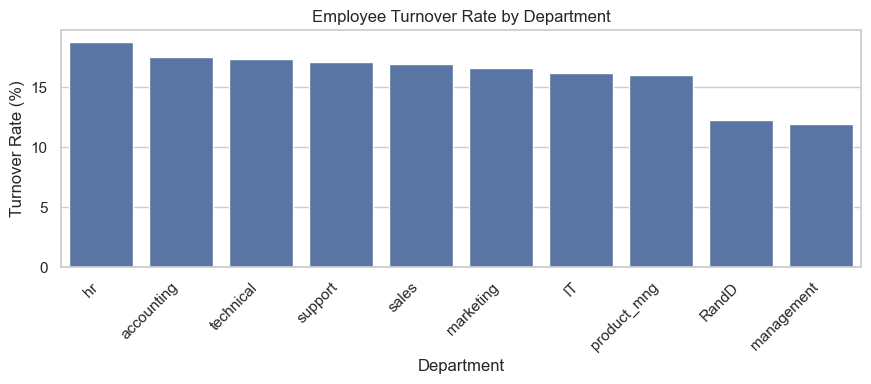

In [29]:
# Calculate turnover percentage by department
department_turnover = (
    df_clean.groupby('Department')['left']
    .mean()
    .sort_values(ascending=False) * 100
)
plt.figure(figsize=(9, 4))
sns.barplot(x=department_turnover.index, y=department_turnover.values)

plt.title('Employee Turnover Rate by Department')
plt.xlabel('Department')
plt.ylabel('Turnover Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('employee_turnover_by_department.png', dpi=300, bbox_inches='tight')
plt.show()

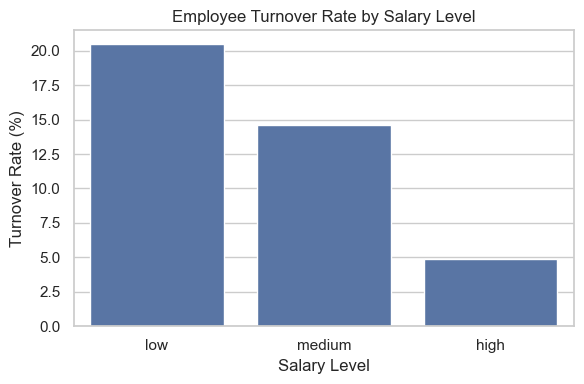

In [30]:
# Calculate turnover percentage by salary level
salary_turnover = (
    df_clean.groupby('salary')['left']
    .mean()
    .reindex(['low', 'medium', 'high']) * 100
)
plt.figure(figsize=(6, 4))
sns.barplot(x=salary_turnover.index, y=salary_turnover.values)

plt.title('Employee Turnover Rate by Salary Level')
plt.xlabel('Salary Level')
plt.ylabel('Turnover Rate (%)')

plt.tight_layout()
plt.savefig('employee_turnover_by_salary_level.png', dpi=300, bbox_inches='tight')
plt.show()

### Salary and Department — Key Findings

- **Salary:** Turnover was highest among low-paid employees (20.4%) and lowest among high-paid employees (4.8%).
- **Department:** HR recorded the highest turnover (18.7%), while management and R&D had the lowest (12%).

**Insight:** Lower salary levels are associated with higher employee turnover, while departmental differences are relatively modest.

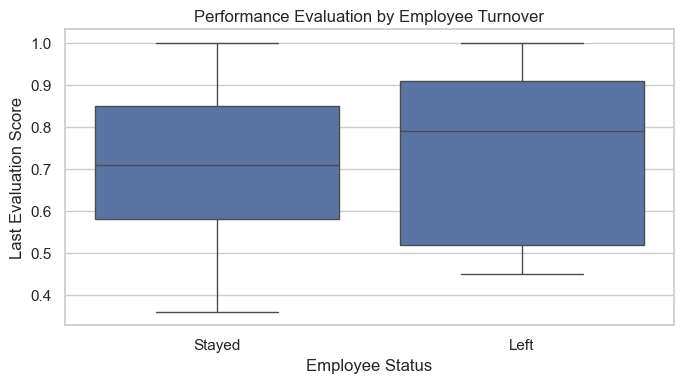

In [32]:
# Compare performance evaluation scores by turnover status
plt.figure(figsize=(7, 4))

sns.boxplot(data=df_clean, x='left', y='last_evaluation')

plt.title('Performance Evaluation by Employee Turnover')
plt.xlabel('Employee Status')
plt.ylabel('Last Evaluation Score')
plt.xticks([0, 1], ['Stayed', 'Left'])

plt.tight_layout()
plt.show()

In [33]:
# Compare average and median evaluation scores
df_clean.groupby('left')['last_evaluation'].agg(['mean', 'median']).round(2)

,mean,median
left,,
0,0.72,0.71
1,0.72,0.79


### Performance Evaluation — Key Findings

Employees who left had a higher median evaluation score (0.79) than those who stayed (0.71), although both groups had the same mean (0.72).

**Insight:** Employee turnover affects both lower- and higher-performing employees, suggesting that performance alone does not explain departures.

### EDA — Overall Summary

- **Turnover:** 16.60% of employees left the company.
- **Satisfaction:** Departing employees generally reported lower satisfaction.
- **Workload:** Turnover was associated with unusually low or high project workloads and longer working hours.
- **Tenure:** Departures were concentrated among employees with 3–5 years of service.
- **Promotion:** Most departing employees had not received recent promotions.
- **Salary:** Lower-paid employees experienced higher turnover rates.
- **Performance:** Departing employees had a higher median evaluation score (0.79) than those who stayed (0.71).

**Conclusion:** Employee satisfaction, workload, tenure, salary and performance evaluation are relevant factors to investigate through predictive modelling. These associations do not establish causation.

## Model Preparation

In [37]:
# Create a copy for modelling
df_model = df_clean.copy()

# Encode salary levels in order
salary_map = {'low': 0, 'medium': 1, 'high': 2}
df_model['salary'] = df_model['salary'].map(salary_map)

# Convert departments into dummy variables
df_model = pd.get_dummies(
    df_model,
    columns=['Department'],
    drop_first=True,
    dtype=int
)
# Preview the encoded dataset
df_model.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,salary,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical
0,0.38,0.53,2,157,3,0,1,0,0,0,0,0,0,0,0,1,0,0
1,0.80,0.86,5,262,6,0,1,0,1,0,0,0,0,0,0,1,0,0
2,0.11,0.88,7,272,4,0,1,0,1,0,0,0,0,0,0,1,0,0
3,0.72,0.87,5,223,5,0,1,0,0,0,0,0,0,0,0,1,0,0
4,0.37,0.52,2,159,3,0,1,0,0,0,0,0,0,0,0,1,0,0


In [38]:
# Define independent and dependent variables
X = df_model.drop(columns='left')
y = df_model['left']

print("Predictor variables:", X.shape)
print("Target variable:", y.shape)

Predictor variables: (11991, 17)
Target variable: (11991,)


In [39]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining turnover rate:", round(y_train.mean() * 100, 2), "%")
print("Testing turnover rate:", round(y_test.mean() * 100, 2), "%")

Training set: (8993, 17)
Testing set: (2998, 17)

Training turnover rate: 16.6 %
Testing turnover rate: 16.61 %


In [40]:
# Confirm that all predictors are numeric
print(X_train.dtypes.value_counts())

# Check for missing values
print("Missing values:", X_train.isnull().sum().sum())

int32      9
int64      6
float64    2
Name: count, dtype: int64
Missing values: 0


### Model Preparation — Key Findings
- **Predictors:** 17 numerical features were prepared for classification.
- **Data split:** 8,993 training records (75%) and 2,998 testing records (25%).
- **Class distribution:** Turnover remained consistent across training (16.60%) and testing (16.61%) sets.

**Conclusion:** The data has been prepared for model development, subject to final preprocessing checks.

### Logistic Regression — Outlier Assessment

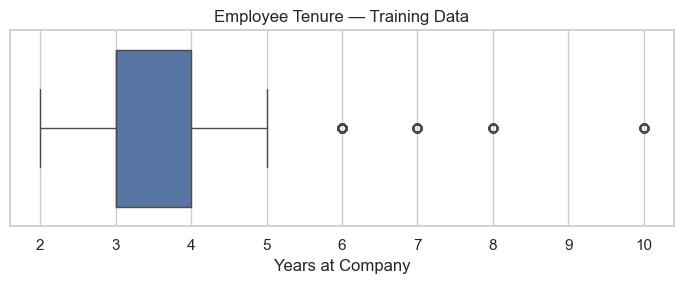

In [43]:
# Visualise employee tenure
plt.figure(figsize=(7, 3))

sns.boxplot(x=X_train['time_spend_company'])

plt.title('Employee Tenure — Training Data')
plt.xlabel('Years at Company')

plt.tight_layout()
plt.show()

In [44]:
# Calculate IQR boundaries for employee tenure
Q1 = X_train['time_spend_company'].quantile(0.25)
Q3 = X_train['time_spend_company'].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

print("Upper outlier limit:", upper_limit)
print("Number of upper outliers:",
      (X_train['time_spend_company'] > upper_limit).sum())

Upper outlier limit: 5.5
Number of upper outliers: 638


### Tenure Outlier Assessment — Key Findings

- **Upper IQR limit:** 5.5 years.
- **Outliers:** 638 training records (7.09%) exceed this threshold.
- **Decision:** Retain these records initially, as longer tenure represents valid employee information.

**Conclusion:** Evaluate Logistic Regression with the original training data before considering outlier treatment.

## Logistic Regression Model

In [47]:
# Identify continuous numerical features
numeric_features = [
    'satisfaction_level',
    'last_evaluation',
    'number_project',
    'average_montly_hours',
    'time_spend_company'
]
# Create copies to preserve the original datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

In [48]:
# Build and train Logistic Regression model
log_model = LogisticRegression(max_iter=1000, random_state=42)

log_model.fit(X_train_scaled, y_train)

# Predict employee turnover
y_pred_log = log_model.predict(X_test_scaled)

In [49]:
# Evaluate Logistic Regression performance
print("Accuracy:", round(accuracy_score(y_test, y_pred_log), 4))
print("Precision:", round(precision_score(y_test, y_pred_log), 4))
print("Recall:", round(recall_score(y_test, y_pred_log), 4))
print("F1-score:", round(f1_score(y_test, y_pred_log), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

Accuracy: 0.8346
Precision: 0.5055
Recall: 0.1847
F1-score: 0.2706

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91      2500
           1       0.51      0.18      0.27       498

    accuracy                           0.83      2998
   macro avg       0.68      0.57      0.59      2998
weighted avg       0.80      0.83      0.80      2998



### Logistic Regression — Key Findings

- **Accuracy:** 83.46%, indicating strong overall classification accuracy.
- **Precision:** 50.55%, while recall was only 18.47%.
- **F1-score:** 27.06%, reflecting limited performance in identifying departing employees.

**Conclusion:** Logistic Regression performs well at identifying retained employees but misses many actual departures.

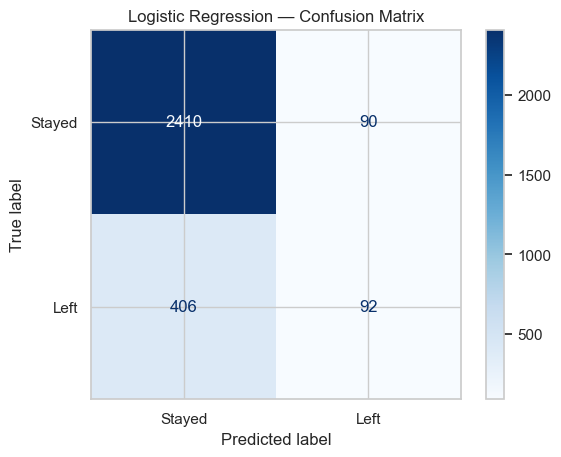

In [51]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_log)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed', 'Left']
)
disp.plot(cmap='Blues')
plt.title('Logistic Regression — Confusion Matrix')
plt.show()

### Confusion Matrix — Key Findings

- **Correct predictions:** 2,410 retained employees and 92 departing employees.
- **Prediction errors:** 90 false positives and 406 false negatives.
- **Recall:** Only 18.47% of actual departures were correctly identified.

**Conclusion:** Logistic Regression misses most departing employees, limiting its effectiveness for employee retention planning.

## Decision Tree Model

In [54]:
# Build and train a baseline Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
# Generate predictions
y_pred_dt = dt_model.predict(X_test)

In [55]:
# Evaluate Decision Tree performance
print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt), 4))
print("F1-score:", round(f1_score(y_test, y_pred_dt), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.9683
Precision: 0.8974
Recall: 0.9137
F1-score: 0.9055

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      2500
           1       0.90      0.91      0.91       498

    accuracy                           0.97      2998
   macro avg       0.94      0.95      0.94      2998
weighted avg       0.97      0.97      0.97      2998



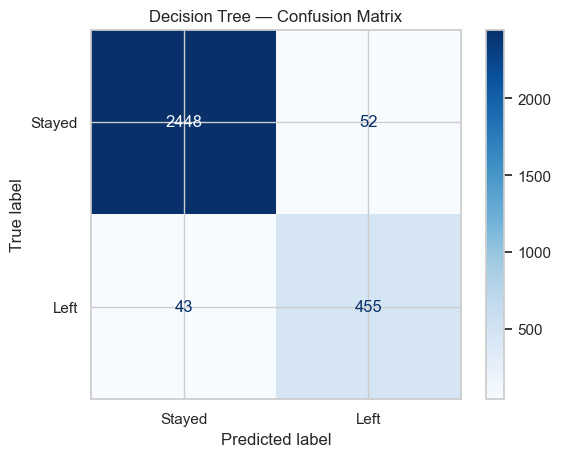

In [56]:
# Display Decision Tree confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=['Stayed', 'Left']
)
disp.plot(cmap='Blues')
plt.title('Decision Tree — Confusion Matrix')
plt.show()

### Decision Tree — Key Findings

- **Performance:** Accuracy reached 96.83%, with precision of 89.74%, recall of 91.37%, and F1-score of 90.55%.
- **Churn detection:** The model correctly identified 455 of 498 departing employees, missing only 43.

**Conclusion:** Decision Tree substantially outperformed Logistic Regression, although cross-validation is needed to assess generalisation and potential overfitting.

### Decision Tree — Hyperparameter Tuning

In [59]:
# Define parameters for tuning
dt_params = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [2, 5, 10],
    'min_samples_split': [2, 5, 10]
}
# Configure GridSearchCV
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)
# Fit using training data only
dt_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [4, 6, 8, 10],
                         'min_samples_leaf': [2, 5, 10],
                         'min_samples_split': [2, 5, 10]},
             scoring='f1')

In [60]:
# Display the best tuning results
print("Best parameters:", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 4))

Best parameters: {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV F1-score: 0.9464


### Decision Tree Tuning — Key Findings
GridSearchCV selected a maximum depth of 8, minimum leaf size of 2, and minimum split size of 10, achieving a cross-validation F1-score of 94.64%.

**Next:** Evaluate the tuned model on unseen test data and compare it with the baseline.

In [62]:
# Retrieve the best Decision Tree model
dt_tuned = dt_grid.best_estimator_
# Predict using the test dataset
y_pred_dt_tuned = dt_tuned.predict(X_test)


In [63]:
# Evaluate tuned Decision Tree
print("Accuracy:", round(accuracy_score(y_test, y_pred_dt_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_dt_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned))

Accuracy: 0.983
Precision: 0.9686
Recall: 0.9277
F1-score: 0.9477

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2500
           1       0.97      0.93      0.95       498

    accuracy                           0.98      2998
   macro avg       0.98      0.96      0.97      2998
weighted avg       0.98      0.98      0.98      2998



In [64]:
# Compare Decision Tree performance
dt_comparison = pd.DataFrame({
    'Model': ['Baseline Decision Tree', 'Tuned Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_dt_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt_tuned)
    ],
    'Recall': [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt_tuned)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt_tuned)
    ]
})
dt_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline Decision Tree,0.9683,0.8974,0.9137,0.9055
1,Tuned Decision Tree,0.9830,0.9686,0.9277,0.9477


### Decision Tree — Model Comparison

- **Baseline:** Achieved 96.83% accuracy and 90.55% F1-score.
- **Tuned:** Improved to 98.30% accuracy, 96.86% precision, 92.77% recall, and 94.77% F1-score.

**Conclusion:** Hyperparameter tuning improved Decision Tree performance across all evaluation metrics, making the tuned model the stronger candidate.

## Random Forest Model

In [67]:
# Build and train the baseline Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
# Generate predictions
y_pred_rf = rf_model.predict(X_test)

In [68]:
# Evaluate baseline Random Forest
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.9857
Precision: 0.9914
Recall: 0.9217
F1-score: 0.9553

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2500
           1       0.99      0.92      0.96       498

    accuracy                           0.99      2998
   macro avg       0.99      0.96      0.97      2998
weighted avg       0.99      0.99      0.99      2998



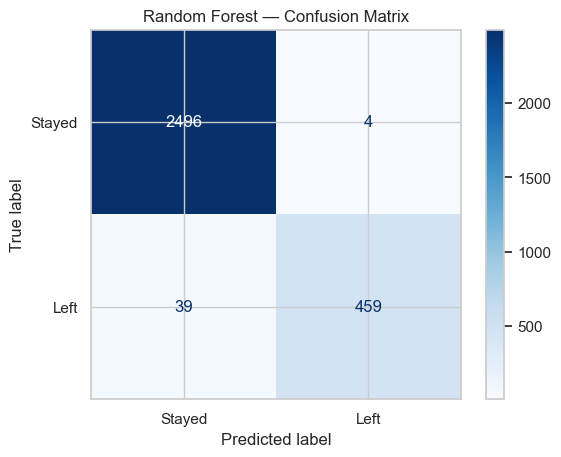

In [69]:
# Display Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Stayed', 'Left']
)
disp.plot(cmap='Blues')
plt.title('Random Forest — Confusion Matrix')
plt.show()

### Random Forest — Key Findings

- **Performance:** Accuracy reached 98.57%, precision 99.14%, recall 92.17%, and F1-score 95.53%.
- **Churn detection:** Correctly identified 459 of 498 departing employees, with 39 false negatives and 4 false positives.

**Conclusion:** Random Forest achieved strong classification performance, although cross-validation is needed to assess its generalisation.

### Random Forest — Hyperparameter Tuning

In [72]:
# Define Random Forest hyperparameters
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12, None],
    'min_samples_leaf': [1, 2, 4]
}
# Configure GridSearchCV
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)
# Fit on training data
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [8, 12, None],
                         'min_samples_leaf': [1, 2, 4],
                         'n_estimators': [100, 200]},
             scoring='f1')

In [73]:
# Display best hyperparameters and CV performance
print("Best parameters:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV F1-score: 0.9477


### Random Forest Tuning — Key Findings

GridSearchCV selected 100 trees, unlimited tree depth, and a minimum leaf size of 1, achieving a cross-validation F1-score of 94.77%.

**Conclusion:** The optimal parameters matched the baseline configuration, suggesting limited improvement from tuning within the tested parameter grid.

In [75]:
# Retrieve the best Random Forest model
rf_tuned = rf_grid.best_estimator_

# Generate predictions on test data
y_pred_rf_tuned = rf_tuned.predict(X_test)

In [76]:
# Evaluate tuned Random Forest
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf_tuned), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

Accuracy: 0.9857
Precision: 0.9914
Recall: 0.9217
F1-score: 0.9553

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2500
           1       0.99      0.92      0.96       498

    accuracy                           0.99      2998
   macro avg       0.99      0.96      0.97      2998
weighted avg       0.99      0.99      0.99      2998



In [77]:
# Compare baseline and tuned Random Forest
rf_comparison = pd.DataFrame({
    'Model': ['Baseline Random Forest', 'Tuned Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_tuned)
    ],
    'Recall': [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_tuned)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_tuned)
    ]
})

rf_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline Random Forest,0.9857,0.9914,0.9217,0.9553
1,Tuned Random Forest,0.9857,0.9914,0.9217,0.9553


### Random Forest — Model Comparison

- **Baseline and tuned models:** Both achieved 98.57% accuracy, 99.14% precision, 92.17% recall, and 95.53% F1-score.
- **Tuning outcome:** GridSearchCV selected the baseline parameters, producing identical results.

**Conclusion:** Random Forest demonstrated strong predictive performance without further improvement from hyperparameter tuning.

## XGBoost Model Development

In [80]:
# Import XGBoost classifier
from xgboost import XGBClassifier

# Build baseline XGBoost model
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

In [81]:
# Evaluate baseline XGBoost
print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb), 4))
print("Recall:", round(recall_score(y_test, y_pred_xgb), 4))
print("F1-score:", round(f1_score(y_test, y_pred_xgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.9833
Precision: 0.9726
Recall: 0.9257
F1-score: 0.9486

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2500
           1       0.97      0.93      0.95       498

    accuracy                           0.98      2998
   macro avg       0.98      0.96      0.97      2998
weighted avg       0.98      0.98      0.98      2998



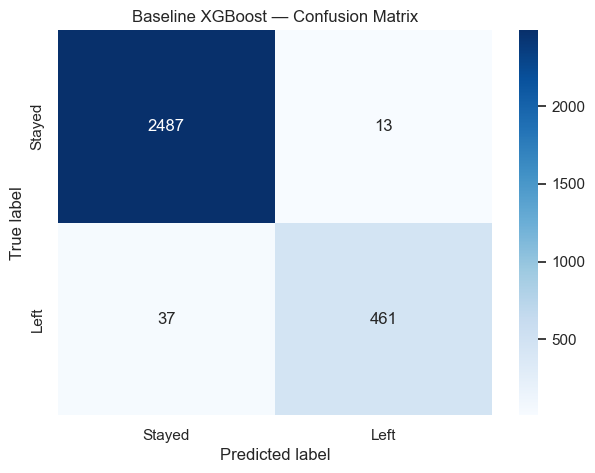

In [82]:
# Plot XGBoost confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)
plt.title('Baseline XGBoost — Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()


### Baseline XGBoost — Key Findings

- **Performance:** Accuracy reached 98.33%, precision 97.26%, recall 92.57%, and F1-score 94.86%.
- **Turnover detection:** Correctly identified 461 of 498 departing employees, with 37 false negatives and 13 false positives.

**Conclusion:** XGBoost demonstrated strong predictive performance and slightly higher recall than Random Forest, although Random Forest achieved a higher F1-score.

###  XGBoost Hyperparameter Tuning

In [85]:
# Define XGBoost hyperparameters
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}
# Configure GridSearchCV
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=1
    ),
    param_grid=xgb_params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)
# Fit using training data only
xgb_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraint...
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=1, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.05, 0.1], 'max_depth': [3, 5],
                         'n_estimators': [100, 200]},
             scoring='f1')

In [86]:
# Display best parameters and CV performance
print("Best parameters:", xgb_grid.best_params_)
print("Best CV F1-score:", round(xgb_grid.best_score_, 4))

Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best CV F1-score: 0.9472


### XGBoost Tuning — Key Findings

GridSearchCV selected a learning rate of 0.05, maximum tree depth of 5, and 200 estimators, achieving a five-fold cross-validation F1-score of 94.72%.

**Next:** Evaluate the tuned XGBoost model and compare its performance with the baseline.

In [88]:
# Retrieve the best XGBoost model
xgb_tuned = xgb_grid.best_estimator_
# Generate predictions
y_pred_xgb_tuned = xgb_tuned.predict(X_test)

In [89]:
# Evaluate tuned XGBoost
print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_xgb_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_xgb_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_tuned))

Accuracy: 0.9847
Precision: 0.9788
Recall: 0.9277
F1-score: 0.9526

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2500
           1       0.98      0.93      0.95       498

    accuracy                           0.98      2998
   macro avg       0.98      0.96      0.97      2998
weighted avg       0.98      0.98      0.98      2998



### XGBoost Model Comparison — Key Findings

- **Baseline:** Achieved 98.33% accuracy and 94.86% F1-score.
- **Tuned:** Improved to 98.47% accuracy, 97.88% precision, 92.77% recall, and 95.26% F1-score.

**Conclusion:** Hyperparameter tuning improved XGBoost performance across all metrics, making the tuned model the stronger XGBoost candidate.

## Overall Model Comparison

In [92]:
# Store predictions from all seven models
models = {
    'Logistic Regression': y_pred_log,
    'Baseline Decision Tree': y_pred_dt,
    'Tuned Decision Tree': y_pred_dt_tuned,
    'Baseline Random Forest': y_pred_rf,
    'Tuned Random Forest': y_pred_rf_tuned,
    'Baseline XGBoost': y_pred_xgb,
    'Tuned XGBoost': y_pred_xgb_tuned
}
# Calculate evaluation metrics
results = []
for name, predictions in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-score': f1_score(y_test, predictions)
    })
model_comparison = pd.DataFrame(results)

# Rank models by F1-score
model_comparison = model_comparison.sort_values(
    by='F1-score',
    ascending=False
)
model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
3,Baseline Random Forest,0.9857,0.9914,0.9217,0.9553
4,Tuned Random Forest,0.9857,0.9914,0.9217,0.9553
6,Tuned XGBoost,0.9847,0.9788,0.9277,0.9526
5,Baseline XGBoost,0.9833,0.9726,0.9257,0.9486
2,Tuned Decision Tree,0.9830,0.9686,0.9277,0.9477
1,Baseline Decision Tree,0.9683,0.8974,0.9137,0.9055
0,Logistic Regression,0.8346,0.5055,0.1847,0.2706


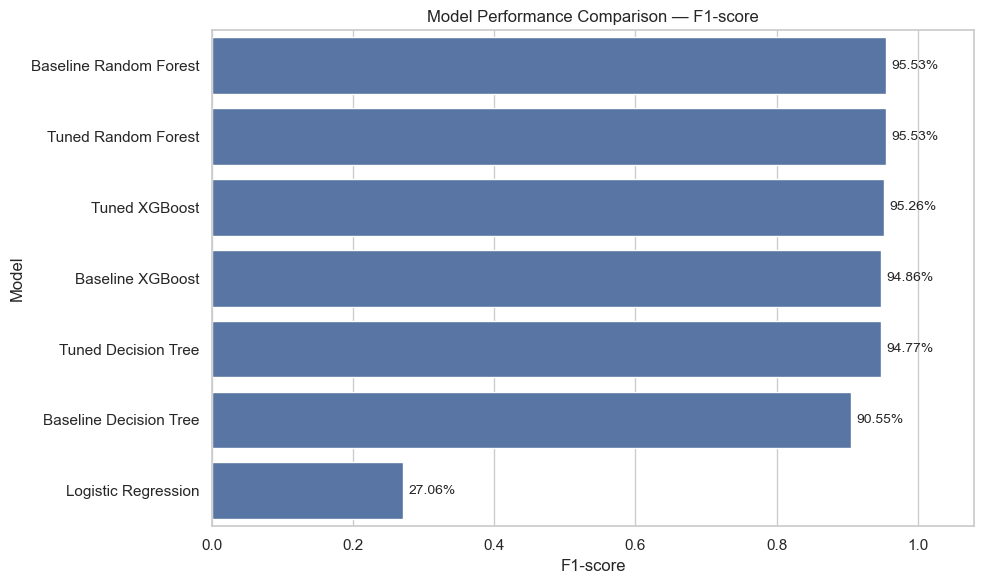

In [93]:
# Compare model F1-scores
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=model_comparison.sort_values('F1-score', ascending=False),
    x='F1-score',
    y='Model'
)

plt.title('Model Performance Comparison — F1-score')
plt.xlabel('F1-score')
plt.ylabel('Model')
plt.xlim(0, 1.08)
# Display F1-score percentages at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{bar.get_width() * 100:.2f}%' for bar in container],
        padding=4,
        fontsize=10
    )
plt.tight_layout()
# Save chart as a high-quality image
plt.savefig('model_f1_score_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Overall Model Comparison — Key Findings

- **Random Forest:** Highest accuracy (98.57%), precision (99.14%), and F1-score (95.53%).
- **Tuned XGBoost:** Achieved 98.47% accuracy and 95.26% F1-score, ranking second overall.
- **Recall:** Tuned XGBoost and Tuned Decision Tree achieved the highest recall (92.77%).
- **Logistic Regression:** Lowest F1-score (27.06%) and recall (18.47%).

**Conclusion:** Random Forest is the strongest overall candidate based on F1-score, while Tuned XGBoost offers competitive performance with slightly higher recall. Further validation is recommended before deployment.

## Feature Importance Analysis

In [96]:
# Extract Random Forest feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_tuned.feature_importances_
})
# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)
# Display the top 10 features
feature_importance.head(10).round(4)


,Feature,Importance
0,satisfaction_level,0.3251
2,number_project,0.1805
4,time_spend_company,0.1672
3,average_montly_hours,0.1638
1,last_evaluation,0.1257
7,salary,0.0107
5,Work_accident,0.0071
14,Department_sales,0.0034
16,Department_technical,0.0033
15,Department_support,0.0031


### Feature Importance — Key Findings

- **Satisfaction:** Most influential predictor (32.51%).
- **Workload:** Number of projects (18.05%) and monthly hours (16.38%) were important.
- **Tenure and performance:** Years at company (16.72%) and evaluation scores (12.57%) also contributed substantially.

**Conclusion:** Satisfaction, workload, tenure, and performance were the strongest predictors of employee turnover. Feature importance does not establish causation.

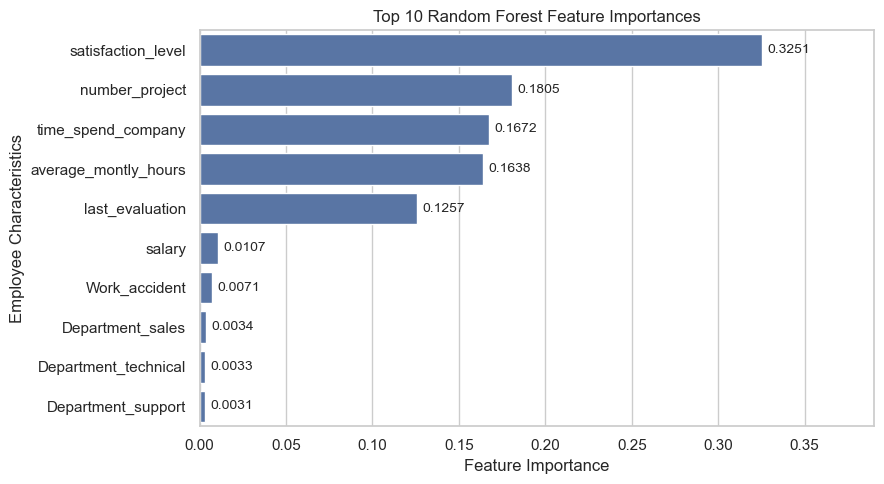

In [98]:
# Visualise the top 10 important features
top_features = feature_importance.head(10)
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)
plt.title('Top 10 Random Forest Feature Importances')
plt.xlabel('Feature Importance')
plt.ylabel('Employee Characteristics')
# Display importance values at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{bar.get_width():.4f}' for bar in container],
        padding=4,
        fontsize=10
    )
# Add space for the labels
plt.xlim(0, top_features['Importance'].max() * 1.20)

plt.tight_layout()
# Save chart as a high-quality PNG image
plt.savefig('random_forest_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

### XGBoost Feature Importance Analysis

In [100]:
# Extract XGBoost feature importance
xgb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_tuned.feature_importances_
})
# Sort features by importance
xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)
# Display the top 10 features
xgb_importance.head(10).round(4)

,Feature,Importance
0,satisfaction_level,0.3522
4,time_spend_company,0.2748
2,number_project,0.1292
1,last_evaluation,0.1008
3,average_montly_hours,0.0474
5,Work_accident,0.0266
7,salary,0.0233
11,Department_management,0.0150
14,Department_sales,0.0107
15,Department_support,0.0086


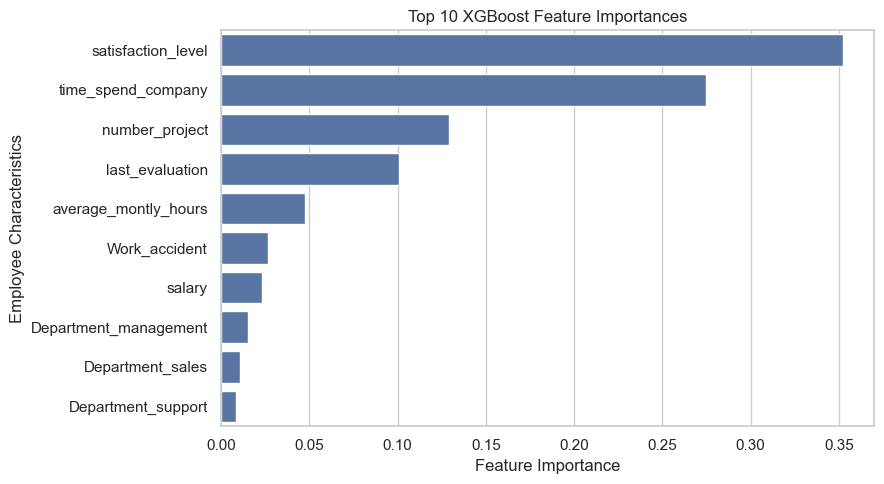

In [101]:
# Visualise the top 10 XGBoost features
plt.figure(figsize=(9, 5))

sns.barplot(
    data=xgb_importance.head(10),
    x='Importance',
    y='Feature'
)
plt.title('Top 10 XGBoost Feature Importances')
plt.xlabel('Feature Importance')
plt.ylabel('Employee Characteristics')

plt.tight_layout()
plt.show()

### XGBoost Feature Importance — Key Findings

- **Satisfaction:** Most influential predictor (35.22%).
- **Tenure:** Years at company ranked second (27.48%).
- **Workload and performance:** Number of projects (12.92%), evaluation scores (10.08%), and monthly hours (4.74%) also contributed.

**Conclusion:** Satisfaction and tenure were the strongest XGBoost predictors, supporting the importance of employee engagement and retention monitoring.

## Model Validation and Reproducibility Checks

In [104]:
# Check that the target is excluded from predictors
print("Target in predictors:", 'left' in X_train.columns)

# Check for missing values
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

# Check dataset dimensions
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Target in predictors: False
Training missing values: 0
Testing missing values: 0
Training shape: (8993, 17)
Testing shape: (2998, 17)


In [105]:
# Check for overlapping predictor records
train_rows = set(map(tuple, X_train.to_numpy()))
test_rows = set(map(tuple, X_test.to_numpy()))

overlapping_rows = len(train_rows.intersection(test_rows))

print("Overlapping predictor records:", overlapping_rows)

Overlapping predictor records: 0


In [106]:
# Compare training and testing F1-scores
validation_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Tuned XGBoost'],
    'Training F1': [
        f1_score(y_train, dt_tuned.predict(X_train)),
        f1_score(y_train, rf_tuned.predict(X_train)),
        f1_score(y_train, xgb_tuned.predict(X_train))
    ],
    'Testing F1': [
        f1_score(y_test, dt_tuned.predict(X_test)),
        f1_score(y_test, rf_tuned.predict(X_test)),
        f1_score(y_test, xgb_tuned.predict(X_test))
    ]
})
# Calculate performance differences
validation_results['F1 Gap'] = (
    validation_results['Training F1'] -
    validation_results['Testing F1']
)
validation_results.round(4)

,Model,Training F1,Testing F1,F1 Gap
0,Tuned Decision Tree,0.9550,0.9477,0.0073
1,Random Forest,0.9997,0.9553,0.0444
2,Tuned XGBoost,0.9560,0.9526,0.0034


In [107]:
# Compare cross-validation F1-scores
cv_comparison = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Tuned Random Forest', 'Tuned XGBoost'],
    'CV F1-score': [
        dt_grid.best_score_,
        rf_grid.best_score_,
        xgb_grid.best_score_
    ]
})
cv_comparison.round(4)

,Model,CV F1-score
0,Tuned Decision Tree,0.9464
1,Tuned Random Forest,0.9477
2,Tuned XGBoost,0.9472


In [108]:
# Confirm model random states
print("Decision Tree:", dt_tuned.random_state)
print("Random Forest:", rf_tuned.random_state)
print("XGBoost:", xgb_tuned.random_state)

Decision Tree: 42
Random Forest: 42
XGBoost: 42


### Model Validation — Key Findings

- **Data integrity:** No missing values, target leakage through direct inclusion, or overlapping predictor records were detected.
- **Random Forest:** Highest test F1-score (95.53%), although its training F1-score (99.97%) suggests some overfitting.
- **XGBoost:** Strong test F1-score (95.26%) with the smallest training–testing gap (0.34 percentage points).
- **Cross-validation:** All three tuned models achieved similar CV F1-scores (94.64%–94.77%).

**Conclusion:** Random Forest achieved the strongest test F1-score, while XGBoost demonstrated greater consistency between training and testing performance. Further validation is recommended before real-world deployment.

## 14. Final Conclusions and Business Recommendations

### Project Summary

This project analysed 11,991 employee records and developed machine learning models to predict employee turnover. Logistic Regression, Decision Tree, Random Forest, and XGBoost were evaluated using accuracy, precision, recall, and F1-score.

### Key Findings

- **Employee turnover:** 16.60% of employees left the company.
- **Best-performing model:** Random Forest achieved 98.57% accuracy, 99.14% precision, 92.17% recall, and a 95.53% F1-score.
- **XGBoost:** The tuned model achieved a 95.26% F1-score and 92.77% recall, identifying a slightly higher proportion of employees who left.
- **Important predictors:** Employee satisfaction, tenure, number of projects, performance evaluation, and monthly working hours were influential predictors.
- **Model validation:** XGBoost showed the smallest training–testing F1 gap, while Random Forest achieved the highest test F1-score.

### Business Recommendations

1. **Improve employee satisfaction:** Conduct regular employee feedback surveys and address workplace concerns.
2. **Monitor workload:** Review project assignments and working hours to identify potential workload pressures.
3. **Support employee development:** Strengthen career progression, promotion opportunities, and employee engagement.
4. **Identify at-risk employees:** Use model predictions to support voluntary retention initiatives, subject to appropriate validation and human oversight.

### Limitations and Future Improvements

- The dataset represents a historical employee turnover scenario and may not reflect current workforce conditions.
- Feature importance indicates predictive relationships, not causation.
- Random Forest showed signs of overfitting, requiring further evaluation.
- Future work should include independent validation, fairness assessments, and monitoring before deployment.

### Final Conclusion

Random Forest achieved the strongest overall test performance, while XGBoost demonstrated greater consistency and slightly higher recall. Employee satisfaction and tenure emerged as particularly important predictors. These findings can inform evidence-based retention strategies, although further validation is necessary before real-world use.